# Proyek Analisis Data: [Bike Sharing Dataset]
- **Nama:** [Nur Nabila Amalia]
- **Email:** [ds128b6x1409@student.devacademy.id]
- **ID Dicoding:** [nur_nabila_amalis139]

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana perbandingan rata-rata penyewaan sepeda harian antara pengguna casual dan registered berdasarkan perubahan musim selama periode 2011 hingga 2012, sebagai dasar penentuan strategi retensi pelanggan dan promosi musiman?
- **Pertanyaan 2:**  Bagaimana pola rata-rata penyewaan sepeda per jam pada hari kerja dibandingkan dengan akhir pekan atau hari libur selama periode 2011 hingga 2012, sebagai dasar penjadwalan pemeliharaan armada dan pengaturan distribusi unit sepeda?

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

## Data Wrangling

In [2]:
day_df = pd.read_csv("data/day.csv")
hour_df = pd.read_csv("data/hour.csv")

day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


### Gathering Data

#### Load Dataset Bike Sharing (Day & Hour)

In [3]:
day_df = pd.read_csv("data/day.csv")
hour_df = pd.read_csv("data/hour.csv")

day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


**Insight:**
- Dataset `day.csv` memuat 731 data penyewaan sepeda harian dan `hour.csv` memuat 17.379 data penyewaan per jam dari tahun 2011–2012.

### Assessing Data

#### Identifying Data Types and Missing Values

In [4]:
print("=== Info day_df ===")
day_df.info()
print("\nMissing value day_df:", day_df.isna().sum().sum())
print("Duplikat day_df:", day_df.duplicated().sum())

print("\n=== Info hour_df ===")
hour_df.info()
print("\nMissing value hour_df:", hour_df.isna().sum().sum())
print("Duplikat hour_df:", hour_df.duplicated().sum())

=== Info day_df ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

Missing value day_df: 0
Duplikat day_df: 0

=== Info hour_df ===
<class 

**Steps to Take:**
- Mengubah tipe data kolom `dteday` dari string/object menjadi `datetime`.
- Mengubah kode angka pada kolom `season`, `yr`, dan `weathersit` menjadi teks keterangan yang jelas.

**Insight:** (Opsional)
- Tidak ada missing value maupun data duplikat pada kedua dataset.
- Masalah yang ditemukan adalah tipe data tanggal (`dteday`) belum berbentuk `datetime` dan beberapa kolom kategori masih memakai angka.
- Terdapat ketidaksesuaian tipe data pada kolom `dteday` di kedua dataset (`day_df` dan `hour_df`) yang masih bertipe `object`, seharusnya diubah menjadi `datetime`.
-  Nilai pada beberapa kolom kategorikal seperti `season` (1–4) dan `workingday` (0 dan 1) masih berbentuk kode angka sehingga perlu diubah menjadi label kategori yang deskriptif agar konsisten dan mudah dibaca pada tahap analisis selanjutnya.

### Cleaning Data

#### Fixing Data Types and Category Labels

In [5]:
# 1. Mengubah tipe data kolom dteday menjadi datetime
day_df["dteday"] = pd.to_datetime(day_df["dteday"])
hour_df["dteday"] = pd.to_datetime(hour_df["dteday"])

# 2. Mengubah kode angka menjadi label kategorikal yang deskriptif
season_map = {1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"}
workingday_map = {0: "Akhir Pekan / Libur", 1: "Hari Kerja"}

day_df["season"] = day_df["season"].map(season_map)
hour_df["season"] = hour_df["season"].map(season_map)

day_df["workingday"] = day_df["workingday"].map(workingday_map)
hour_df["workingday"] = hour_df["workingday"].map(workingday_map)

# 3. Cek ulang hasil cleaning
print("Info day_df setelah cleaning:")
day_df.info()
print("\nSampel data day_df setelah cleaning:")
display(day_df[["dteday", "season", "workingday"]].head())

print("\nInfo hour_df setelah cleaning:")
hour_df.info()
print("\nSampel data hour_df setelah cleaning:")
display(hour_df[["dteday", "season", "workingday"]].head())

Info day_df setelah cleaning:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     731 non-null    int64         
 1   dteday      731 non-null    datetime64[ns]
 2   season      731 non-null    object        
 3   yr          731 non-null    int64         
 4   mnth        731 non-null    int64         
 5   holiday     731 non-null    int64         
 6   weekday     731 non-null    int64         
 7   workingday  731 non-null    object        
 8   weathersit  731 non-null    int64         
 9   temp        731 non-null    float64       
 10  atemp       731 non-null    float64       
 11  hum         731 non-null    float64       
 12  windspeed   731 non-null    float64       
 13  casual      731 non-null    int64         
 14  registered  731 non-null    int64         
 15  cnt         731 non-null    int64         
d

,dteday,season,workingday
0,2011-01-01,Spring,Akhir Pekan / Libur
1,2011-01-02,Spring,Akhir Pekan / Libur
2,2011-01-03,Spring,Hari Kerja
3,2011-01-04,Spring,Hari Kerja
4,2011-01-05,Spring,Hari Kerja



Info hour_df setelah cleaning:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     17379 non-null  int64         
 1   dteday      17379 non-null  datetime64[ns]
 2   season      17379 non-null  object        
 3   yr          17379 non-null  int64         
 4   mnth        17379 non-null  int64         
 5   hr          17379 non-null  int64         
 6   holiday     17379 non-null  int64         
 7   weekday     17379 non-null  int64         
 8   workingday  17379 non-null  object        
 9   weathersit  17379 non-null  int64         
 10  temp        17379 non-null  float64       
 11  atemp       17379 non-null  float64       
 12  hum         17379 non-null  float64       
 13  windspeed   17379 non-null  float64       
 14  casual      17379 non-null  int64         
 15  registered  17379 non-null  int64     

,dteday,season,workingday
0,2011-01-01,Spring,Akhir Pekan / Libur
1,2011-01-01,Spring,Akhir Pekan / Libur
2,2011-01-01,Spring,Akhir Pekan / Libur
3,2011-01-01,Spring,Akhir Pekan / Libur
4,2011-01-01,Spring,Akhir Pekan / Libur


## Exploratory Data Analysis (EDA)

### Eksplorasi Musim & Proporsi Pengguna

In [6]:
# Mengatur urutan musim agar kronologis
season_order = ["Spring", "Summer", "Fall", "Winter"]

# Menghitung rata-rata harian casual, registered, dan total berdasarkan musim
season_summary = day_df.groupby("season")[["casual", "registered", "cnt"]].mean().reindex(season_order)

# Menambahkan kolom proporsi (%) pengguna casual dan registered untuk mendukung kesimpulan
season_summary["casual_pct (%)"] = (season_summary["casual"] / season_summary["cnt"]) * 100
season_summary["registered_pct (%)"] = (season_summary["registered"] / season_summary["cnt"]) * 100

display(season_summary.round(2))

,casual,registered,cnt,casual_pct (%),registered_pct (%)
season,,,,,
Spring,334.93,2269.20,2604.13,12.86,87.14
Summer,1106.10,3886.23,4992.33,22.16,77.84
Fall,1202.61,4441.69,5644.30,21.31,78.69
Winter,729.11,3999.05,4728.16,15.42,84.58


### Eksplorasi Jam & Hari Kerja

In [7]:
hour_pivot = hour_df.pivot_table(
    index="hr",
    columns="workingday",
    values="cnt",
    aggfunc="mean"
)

display(hour_pivot.round(2))

workingday,Akhir Pekan / Libur,Hari Kerja
hr,,
0,90.80,36.79
1,69.51,16.55
2,53.17,8.68
3,25.78,4.94
4,8.26,5.43
5,8.69,24.91
6,18.74,102.50
7,43.41,290.61
8,105.65,477.01


## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana perbandingan rata-rata penyewaan sepeda harian antara pengguna *casual* dan *registered* berdasarkan perubahan musim selama periode 2011 hingga 2012, sebagai dasar penentuan strategi retensi pelanggan dan promosi musiman?

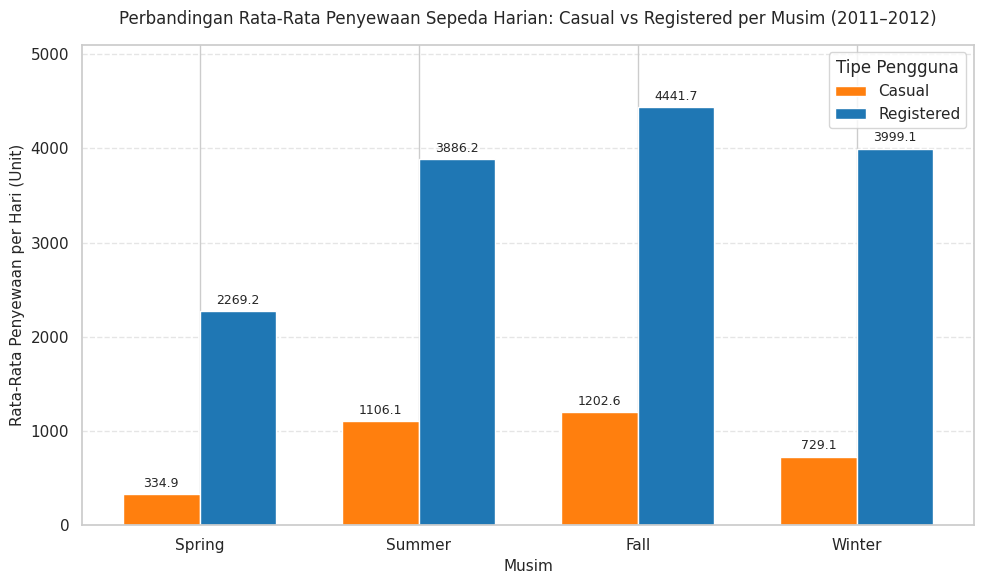

In [8]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
x = np.arange(len(season_summary.index))
width = 0.35

bars_casual = plt.bar(x - width/2, season_summary["casual"], width, label="Casual", color="#ff7f0e")
bars_registered = plt.bar(x + width/2, season_summary["registered"], width, label="Registered", color="#1f77b4")

plt.bar_label(bars_casual, fmt="%.1f", padding=3, fontsize=9)
plt.bar_label(bars_registered, fmt="%.1f", padding=3, fontsize=9)

plt.title("Perbandingan Rata-Rata Penyewaan Sepeda Harian: Casual vs Registered per Musim (2011–2012)", fontsize=12, pad=15)
plt.xlabel("Musim", fontsize=11)
plt.ylabel("Rata-Rata Penyewaan per Hari (Unit)", fontsize=11)
plt.xticks(x, season_summary.index)
plt.ylim(0, 5100)
plt.legend(title="Tipe Pengguna")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### Pertanyaan 2:Bagaimana pola rata-rata penyewaan sepeda per jam pada hari kerja dibandingkan dengan akhir pekan atau hari libur selama periode 2011 hingga 2012, sebagai dasar penjadwalan pemeliharaan armada dan pengaturan distribusi unit sepeda?

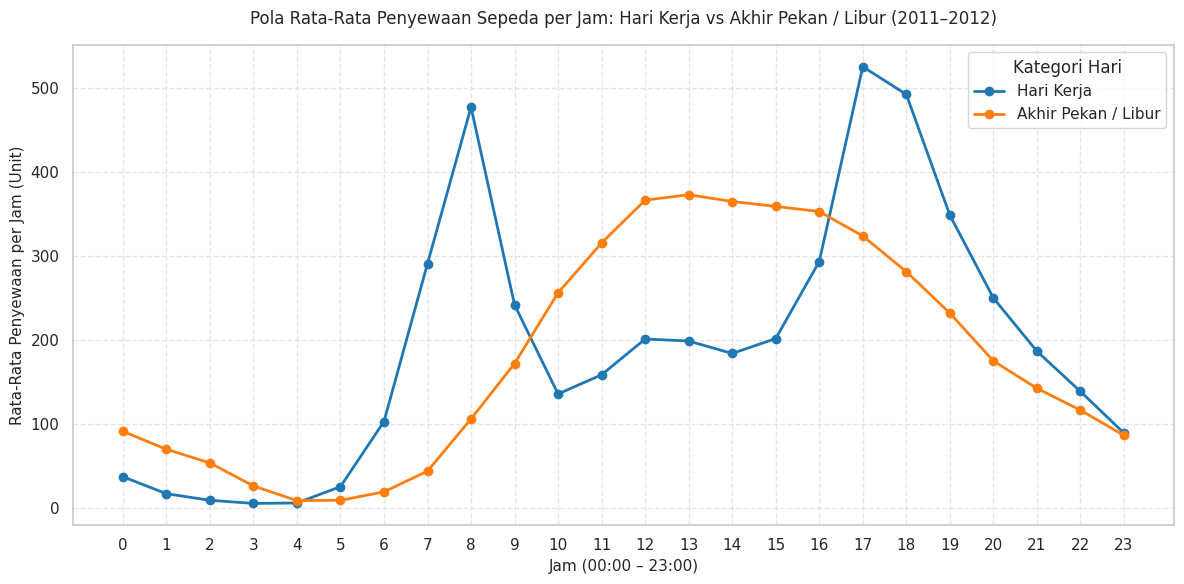

In [9]:
plt.figure(figsize=(12, 6))

plt.plot(hour_pivot.index, hour_pivot["Hari Kerja"], marker="o", linewidth=2, color="#1f77b4", label="Hari Kerja")
plt.plot(hour_pivot.index, hour_pivot["Akhir Pekan / Libur"], marker="o", linewidth=2, color="#ff7f0e", label="Akhir Pekan / Libur")

plt.title("Pola Rata-Rata Penyewaan Sepeda per Jam: Hari Kerja vs Akhir Pekan / Libur (2011–2012)", fontsize=12, pad=15)
plt.xlabel("Jam (00:00 – 23:00)", fontsize=11)
plt.ylabel("Rata-Rata Penyewaan per Jam (Unit)", fontsize=11)
plt.xticks(range(0, 24))
plt.legend(title="Kategori Hari")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## Conclusion & Recommendation

**Conclusion Pertanyaan 1:**
  Sepanjang periode 2011–2012, pengguna *registered* secara konsisten mendominasi penyewaan sepeda di setiap musim dengan rata-rata tertinggi pada musim **Fall** (**4.441,7 penyewaan/hari**) dan terendah pada musim **Spring** (**2.269,2 penyewaan/hari**). Meskipun sama-sama memuncak di musim **Fall** (**1.202,6 penyewaan/hari**), pengguna *casual* mengalami penurunan yang jauh lebih tajam saat beralih ke musim **Spring** (**334,9 penyewaan/hari**), yakni anjlok sekitar **72,2%** dibandingkan penurunan pengguna *registered* yang sebesar **48,9%**. Dari sisi proporsi total penyewaan harian, kontribusi pengguna *casual* berada di titik terendah pada musim **Spring** (sekitar **12,9%**) dan mencapai porsi tertingginya pada musim **Summer** (sekitar **22,2%**).

**Conclusion Pertanyaan 2:**
  Pola permintaan penyewaan sepeda per jam selama periode 2011–2012 terbagi menjadi dua karakteristik waktu yang kontras:
  1. **Hari Kerja:** Permintaan melonjak tajam pada dua waktu utama (*bimodal*), yaitu pukul **08:00** (**477,0 penyewaan/jam**) dan pukul **17:00–18:00** (**525,3** dan **492,2 penyewaan/jam**). Sebaliknya, aktivitas terendah terjadi pada pukul **02:00–04:00** dengan rata-rata di bawah 9 penyewaan/jam (titik terendah pukul **04:00** sebesar **5,4 penyewaan/jam**).
  2. **Akhir Pekan / Libur:** Permintaan meningkat bertahap sejak pagi dan memuncak pada rentang siang hingga sore hari pukul **12:00–16:00**, dengan puncak tertinggi pada pukul **13:00** (**372,7 penyewaan/jam**). Aktivitas terendah terjadi pada pagi buta pukul **05:00–06:00** (titik terendah pukul **06:00** sebesar **18,7 penyewaan/jam**), sementara pada tengah malam pukul **00:00–02:00** penyewaan masih cukup aktif di kisaran **53,2 hingga 90,8 penyewaan/jam**.



### Rekomendasi Action Item
1. **Promosi Musiman & Konversi Keanggotaan (Menjawab Pertanyaan 1):**
   - **Mengatasi penurunan tajam di musim Spring:** Luncurkan program promo diskon tarif sewa harian atau paket *bundling* khusus pengguna *casual* menjelang akhir musim **Winter** hingga **Spring** untuk menahan laju penurunan penyewaan *casual* yang mencapai 72,2%.
   - **Memaksimalkan konversi keanggotaan:** Fokuskan kampanye penawaran uji coba langganan (*membership trial*) pada musim **Summer** dan **Fall**, mengingat pada kedua musim tersebut porsi dan volume pengguna *casual* berada di titik tertinggi (21%–22% dari total penyewaan harian).
2. **Penjadwalan Pemeliharaan & Kesiapan Armada (Menjawab Pertanyaan 2):**
   - **Jadwal perawatan armada:** Lakukan pemeliharaan rutin, perbaikan unit, dan distribusi ulang sepeda pada pukul **02:00–04:00 saat hari kerja** (permintaan < 9 unit/jam) serta pukul **05:00–06:00 saat akhir pekan/hari libur** (permintaan ~18,7 unit/jam), sehingga tidak mengganggu jam operasional dengan permintaan tinggi.
   - **Antisipasi lonjakan armada:** Pastikan seluruh unit sepeda siap digunakan sebelum pukul **07:30** dan **16:30** pada **hari kerja**, serta sebelum pukul **11:30** pada **akhir pekan/hari libur** untuk mengakomodasi jam-jam puncak penyewaan.